In [6]:
# # This mounts your Google Drive to the Colab VM.
# from google.colab import drive
# drive.mount('/content/drive')

# # TODO: Enter the foldername in your Drive where you have saved the unzipped
# # assignment folder, e.g. 'cs231n/assignments/assignment1/'
# FOLDERNAME = 'cs231n/assignments/assignment1/'
# assert FOLDERNAME is not None, "[!] Enter the foldername."

# # Now that we've mounted your Drive, this ensures that
# # the Python interpreter of the Colab VM can load
# # python files from within it.
# import sys
# sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

# # This downloads the CIFAR-10 dataset to your Drive
# # if it doesn't already exist.
# %cd /content/drive/My\ Drive/$FOLDERNAME/cs231n/datasets/
# # %cd /content/drive/My\ Drive/$FOLDERNAME
# !bash get_datasets.sh
# %cd /content/drive/My\ Drive/$FOLDERNAME

# Multi-Layer Fully Connected Network
In this exercise, you will implement a fully connected network with an arbitrary number of hidden layers.

In [7]:
# from google.colab import drive
# drive.mount('/content/drive')

Read through the `FullyConnectedNet` class in the file `cs231n/classifiers/fc_net.py`.

Implement the network initialization, forward pass, and backward pass. Throughout this assignment, you will be implementing layers in `cs231n/layers.py`. You can re-use your implementations for `affine_forward`, `affine_backward`, `relu_forward`, `relu_backward`, and `softmax_loss` from before. For right now, don't worry about implementing dropout or batch/layer normalization yet, as you will add those features later.


In [8]:
# Setup cell.
import time
import numpy as np
import matplotlib.pyplot as plt
from cs231n.classifiers.fc_net import *
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Set default size of plots.
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Returns relative error."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [9]:
# Load the (preprocessed) CIFAR-10 data.
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


## Initial Loss and Gradient Check

As a sanity check, run the following to check the initial loss and to gradient check the network both with and without regularization. This is a good way to see if the initial losses seem reasonable.

For gradient checking, you should expect to see errors around 1e-7 or less.

In [10]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
    print("Running check with reg = ", reg)
    model = FullyConnectedNet(
        [H1, H2],
        input_dim=D,
        num_classes=C,
        reg=reg,
        weight_scale=5e-2,
        dtype=np.float64
    )

    loss, grads = model.loss(X, y)
    print("Initial loss: ", loss)

    # Most of the errors should be on the order of e-7 or smaller.
    # NOTE: It is fine however to see an error for W2 on the order of e-5
    # for the check when reg = 0.0
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print(f"{name} relative error: {rel_error(grad_num, grads[name])}")

Running check with reg =  0
Initial loss:  2.2743465279648425
W1 relative error: 1.206535745219426e-05
W2 relative error: 3.2292243053306805e-05
W3 relative error: 1.8245305562577273e-07
b1 relative error: 3.754569964191523e-07
b2 relative error: 2.158926003735167e-09
b3 relative error: 7.783022498941055e-11
Running check with reg =  3.14
Initial loss:  6.886346766173473
W1 relative error: 3.574579795241046e-08
W2 relative error: 4.560990034596063e-08
W3 relative error: 1.9823571821332328e-08
b1 relative error: 1.0014127753228037e-07
b2 relative error: 6.9017166120126694e-09
b3 relative error: 1.188668671107759e-10


As another sanity check, make sure your network can overfit on a small dataset of 50 images. First, we will try a three-layer network with 100 units in each hidden layer. In the following cell, tweak the **learning rate** and **weight initialization scale** to overfit and achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 3.493389
(Epoch 0 / 20) train acc: 0.280000; val_acc: 0.080000
(Epoch 1 / 20) train acc: 0.340000; val_acc: 0.134000
(Epoch 2 / 20) train acc: 0.440000; val_acc: 0.164000
(Epoch 3 / 20) train acc: 0.700000; val_acc: 0.151000
(Epoch 4 / 20) train acc: 0.700000; val_acc: 0.151000
(Epoch 5 / 20) train acc: 0.900000; val_acc: 0.165000
(Iteration 11 / 40) loss: 0.620341
(Epoch 6 / 20) train acc: 0.960000; val_acc: 0.154000
(Epoch 7 / 20) train acc: 0.920000; val_acc: 0.177000
(Epoch 8 / 20) train acc: 0.880000; val_acc: 0.160000
(Epoch 9 / 20) train acc: 0.960000; val_acc: 0.157000
(Epoch 10 / 20) train acc: 0.960000; val_acc: 0.155000
(Iteration 21 / 40) loss: 0.050500
(Epoch 11 / 20) train acc: 0.960000; val_acc: 0.148000
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.180000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.179000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.174000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.169000
(Iteration 31 / 40) loss: 

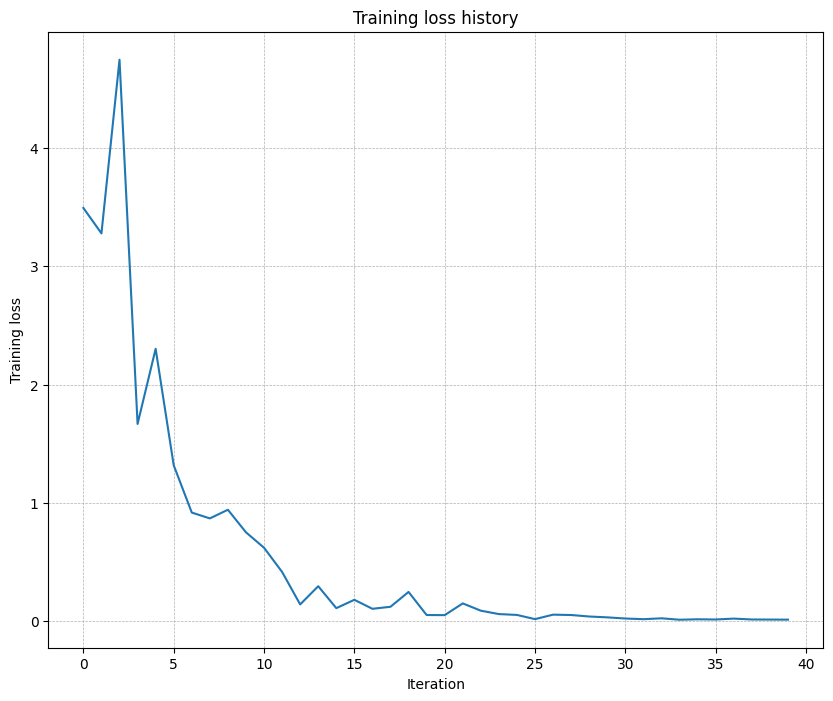

In [11]:
# TODO: Use a three-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  "X_train": data["X_train"][:num_train],
  "y_train": data["y_train"][:num_train],
  "X_val": data["X_val"],
  "y_val": data["y_val"],
}

weight_scale = 2e-2   # Experiment with this!
learning_rate = 1e-2  # Experiment with this!


model = FullyConnectedNet(
    [100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule="sgd",
    optim_config={"learning_rate": learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title("Training loss history")
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.grid(linestyle='--', linewidth=0.5)
plt.show()

Now, try to use a five-layer network with 100 units on each layer to overfit on 50 training examples. Again, you will have to adjust the learning rate and weight initialization scale, but you should be able to achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 4.855603
(Epoch 0 / 20) train acc: 0.180000; val_acc: 0.113000
(Epoch 1 / 20) train acc: 0.280000; val_acc: 0.103000
(Epoch 2 / 20) train acc: 0.480000; val_acc: 0.124000
(Epoch 3 / 20) train acc: 0.640000; val_acc: 0.114000
(Epoch 4 / 20) train acc: 0.740000; val_acc: 0.134000
(Epoch 5 / 20) train acc: 0.940000; val_acc: 0.144000
(Iteration 11 / 40) loss: 0.517471
(Epoch 6 / 20) train acc: 0.960000; val_acc: 0.146000
(Epoch 7 / 20) train acc: 1.000000; val_acc: 0.151000
(Epoch 8 / 20) train acc: 1.000000; val_acc: 0.154000
(Epoch 9 / 20) train acc: 1.000000; val_acc: 0.158000
(Epoch 10 / 20) train acc: 1.000000; val_acc: 0.157000
(Iteration 21 / 40) loss: 0.198392
(Epoch 11 / 20) train acc: 1.000000; val_acc: 0.164000
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.160000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.165000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.163000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.160000
(Iteration 31 / 40) loss: 

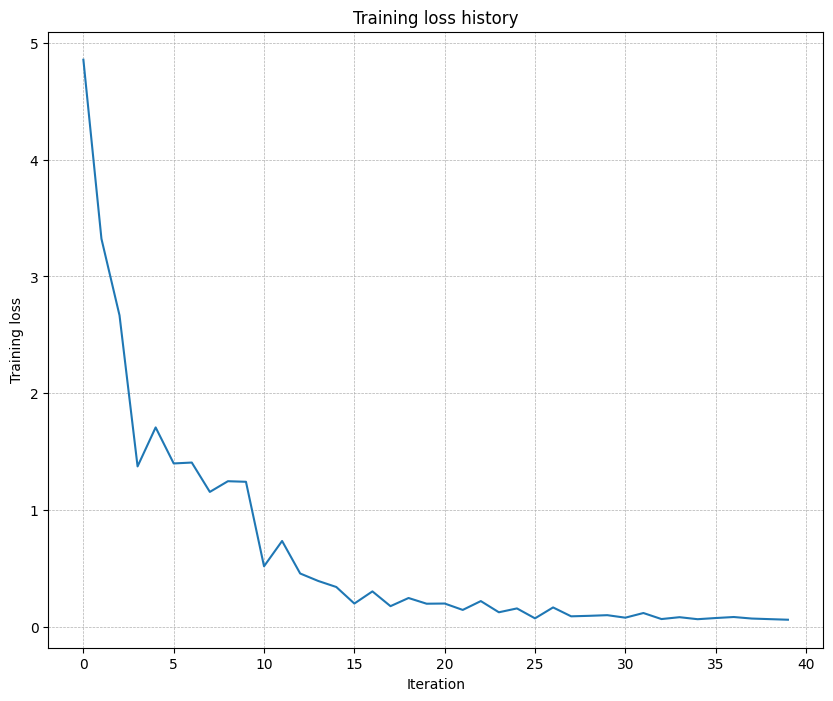

In [12]:
# TODO: Use a five-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate =  5e-3 #1e-3  # Experiment with this!
weight_scale = 5e-2 #1e-1  # Experiment with this!


model = FullyConnectedNet(
    [100, 100, 100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule='sgd',
    optim_config={'learning_rate': learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.grid(linestyle='--', linewidth=0.5)
plt.show()

## Inline Question 1:
Did you notice anything about the comparative difficulty of training the three-layer network vs. training the five-layer network? In particular, based on your experience, which network seemed more sensitive to the initialization scale? Why do you think that is the case?

## Answer:
Training a five layer network is very difficult. This is very sensitive to the tuning parameters `lr` and `ws`. The network is much deeper than 3 layer networks. So if the weight scale is too small, the inputs that gets multiplied by the weights is squished(shrinked) as it pass throught each layer it shrinks more and more and when it reaches layer 5 the activations/output is basically zero. And when you backprop through all these layers the gradients gets squished too (vanishing gradient), so the network can't learn at all. On the other hand if the weight initializations are large activations blow up (exploding gradients). The 3 layer net is more forgiving because there are fewer multiplicaitons, so we have wide range of good initializaitons scales to pick from. With 5 layers you are threading the needle.

The number or layers also makes it harder to tune the learning rate. The learning rate determines the strength of how much we want to correct the weights. In a 5 layer net, if the learning rate is too small, with already a weak signal at loss, we might not be learning anything, if the learning rate to too large we might end blowing the signal and loss blows up. 

# Update rules
So far we have used vanilla stochastic gradient descent (SGD) as our update rule. More sophisticated update rules can make it easier to train deep networks. We will implement a few of the most commonly used update rules and compare them to vanilla SGD.

## SGD+Momentum
Stochastic gradient descent with momentum is a widely used update rule that tends to make deep networks converge faster than vanilla stochastic gradient descent. See the Momentum Update section at http://cs231n.github.io/neural-networks-3/#sgd for more information.

Open the file `cs231n/optim.py` and read the documentation at the top of the file to make sure you understand the API. Implement the SGD+momentum update rule in the function `sgd_momentum` and run the following to check your implementation. You should see errors less than e-8.

In [13]:
from cs231n.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {"learning_rate": 1e-3, "velocity": v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
print("next_w error: ", rel_error(next_w, expected_next_w))
print("velocity error: ", rel_error(expected_velocity, config["velocity"]))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


Once you have done so, run the following to train a six-layer network with both SGD and SGD+momentum. You should see the SGD+momentum update rule converge faster.

Running with  sgd
(Iteration 1 / 200) loss: 3.022533
(Epoch 0 / 5) train acc: 0.116000; val_acc: 0.121000
(Iteration 11 / 200) loss: 2.290065
(Iteration 21 / 200) loss: 2.271979
(Iteration 31 / 200) loss: 2.146908
(Epoch 1 / 5) train acc: 0.230000; val_acc: 0.212000
(Iteration 41 / 200) loss: 2.153933
(Iteration 51 / 200) loss: 2.029760
(Iteration 61 / 200) loss: 2.085056
(Iteration 71 / 200) loss: 2.071240
(Epoch 2 / 5) train acc: 0.273000; val_acc: 0.248000
(Iteration 81 / 200) loss: 1.900616
(Iteration 91 / 200) loss: 1.943393
(Iteration 101 / 200) loss: 1.977783
(Iteration 111 / 200) loss: 2.015236
(Epoch 3 / 5) train acc: 0.351000; val_acc: 0.267000
(Iteration 121 / 200) loss: 1.946415
(Iteration 131 / 200) loss: 1.991292
(Iteration 141 / 200) loss: 1.933257
(Iteration 151 / 200) loss: 1.820310
(Epoch 4 / 5) train acc: 0.368000; val_acc: 0.288000
(Iteration 161 / 200) loss: 1.898291
(Iteration 171 / 200) loss: 1.881386
(Iteration 181 / 200) loss: 1.831910
(Iteration 191 / 200) los

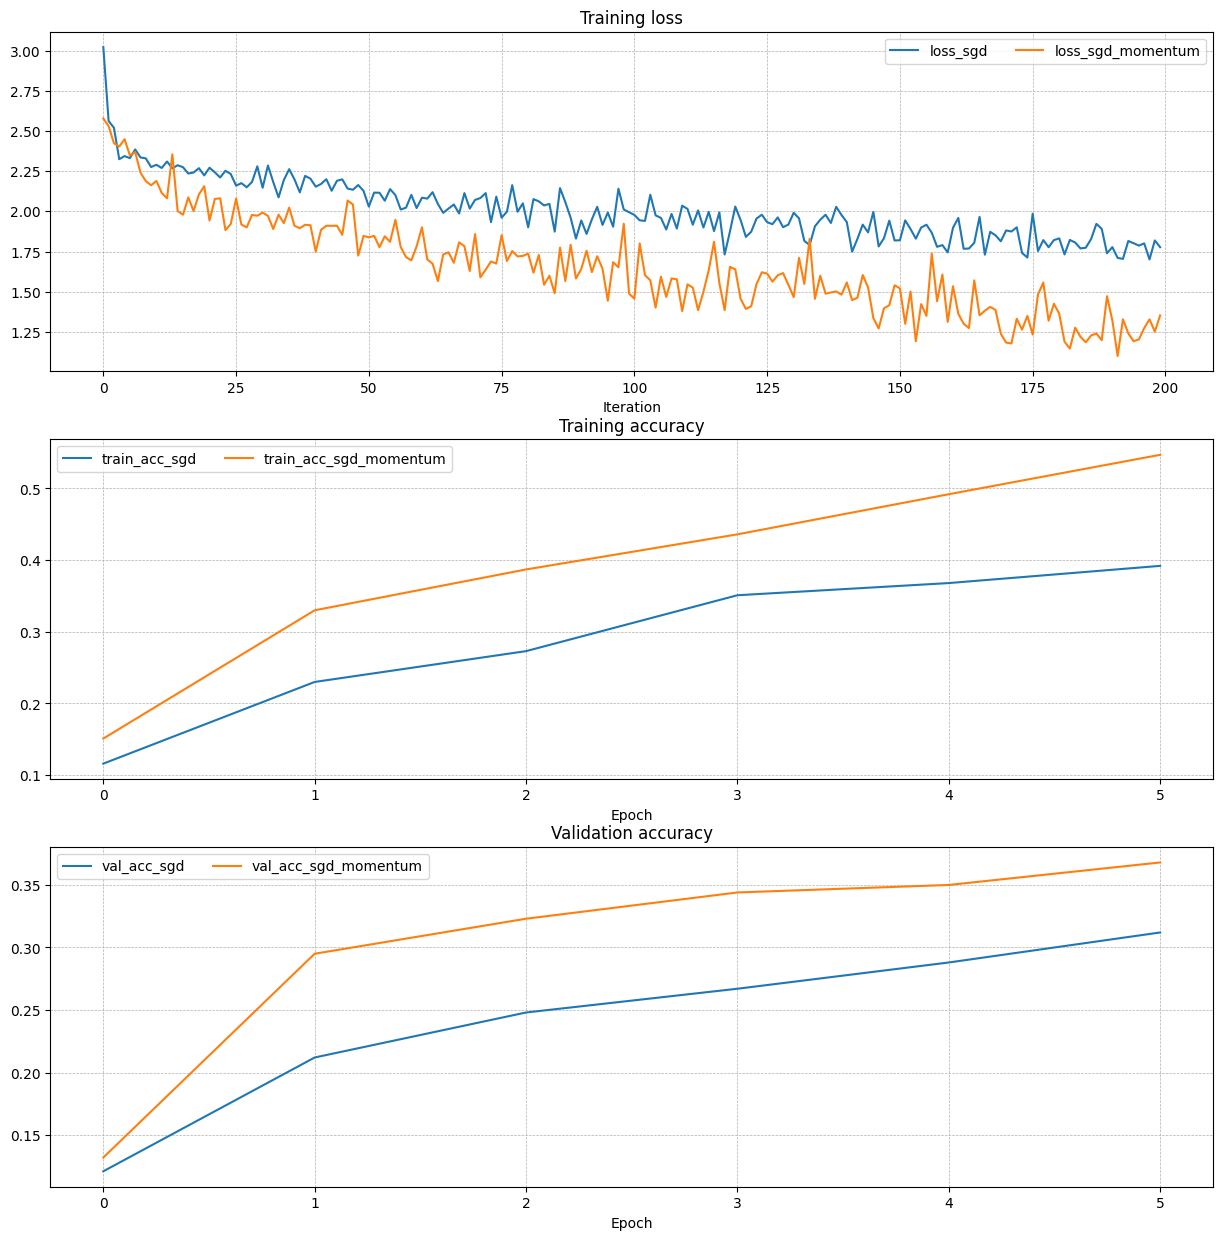

In [14]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
    print('Running with ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )

    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': 5e-3},
        verbose=True,
    )
    solvers[update_rule] = solver
    solver.train()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"loss_{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"train_acc_{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"val_acc_{update_rule}")

for ax in axes:
    ax.legend(loc="best", ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## RMSProp and Adam
RMSProp [1] and Adam [2] are update rules that set per-parameter learning rates by using a running average of the second moments of gradients.

In the file `cs231n/optim.py`, implement the RMSProp update rule in the `rmsprop` function and implement the Adam update rule in the `adam` function, and check your implementations using the tests below.

**NOTE:** Please implement the _complete_ Adam update rule (with the bias correction mechanism), not the first simplified version mentioned in the course notes.

[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [15]:
# Test RMSProp implementation
from cs231n.optim import rmsprop

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


In [16]:
# Test Adam implementation
from cs231n.optim import adam

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  1.1395691798535431e-07
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Once you have debugged your RMSProp and Adam implementations, run the following to train a pair of deep networks using these new update rules:

Running with  adam
(Iteration 1 / 200) loss: 2.977728
(Epoch 0 / 5) train acc: 0.136000; val_acc: 0.147000
(Iteration 11 / 200) loss: 1.992618
(Iteration 21 / 200) loss: 1.851102
(Iteration 31 / 200) loss: 1.849959
(Epoch 1 / 5) train acc: 0.359000; val_acc: 0.321000
(Iteration 41 / 200) loss: 1.834555
(Iteration 51 / 200) loss: 1.677442
(Iteration 61 / 200) loss: 1.781894
(Iteration 71 / 200) loss: 1.768034
(Epoch 2 / 5) train acc: 0.475000; val_acc: 0.347000
(Iteration 81 / 200) loss: 1.513358
(Iteration 91 / 200) loss: 1.523412
(Iteration 101 / 200) loss: 1.649855
(Iteration 111 / 200) loss: 1.357296
(Epoch 3 / 5) train acc: 0.501000; val_acc: 0.380000
(Iteration 121 / 200) loss: 1.369003
(Iteration 131 / 200) loss: 1.323910
(Iteration 141 / 200) loss: 1.468922
(Iteration 151 / 200) loss: 1.335295
(Epoch 4 / 5) train acc: 0.582000; val_acc: 0.382000
(Iteration 161 / 200) loss: 1.288737
(Iteration 171 / 200) loss: 1.363697
(Iteration 181 / 200) loss: 1.218170
(Iteration 191 / 200) lo

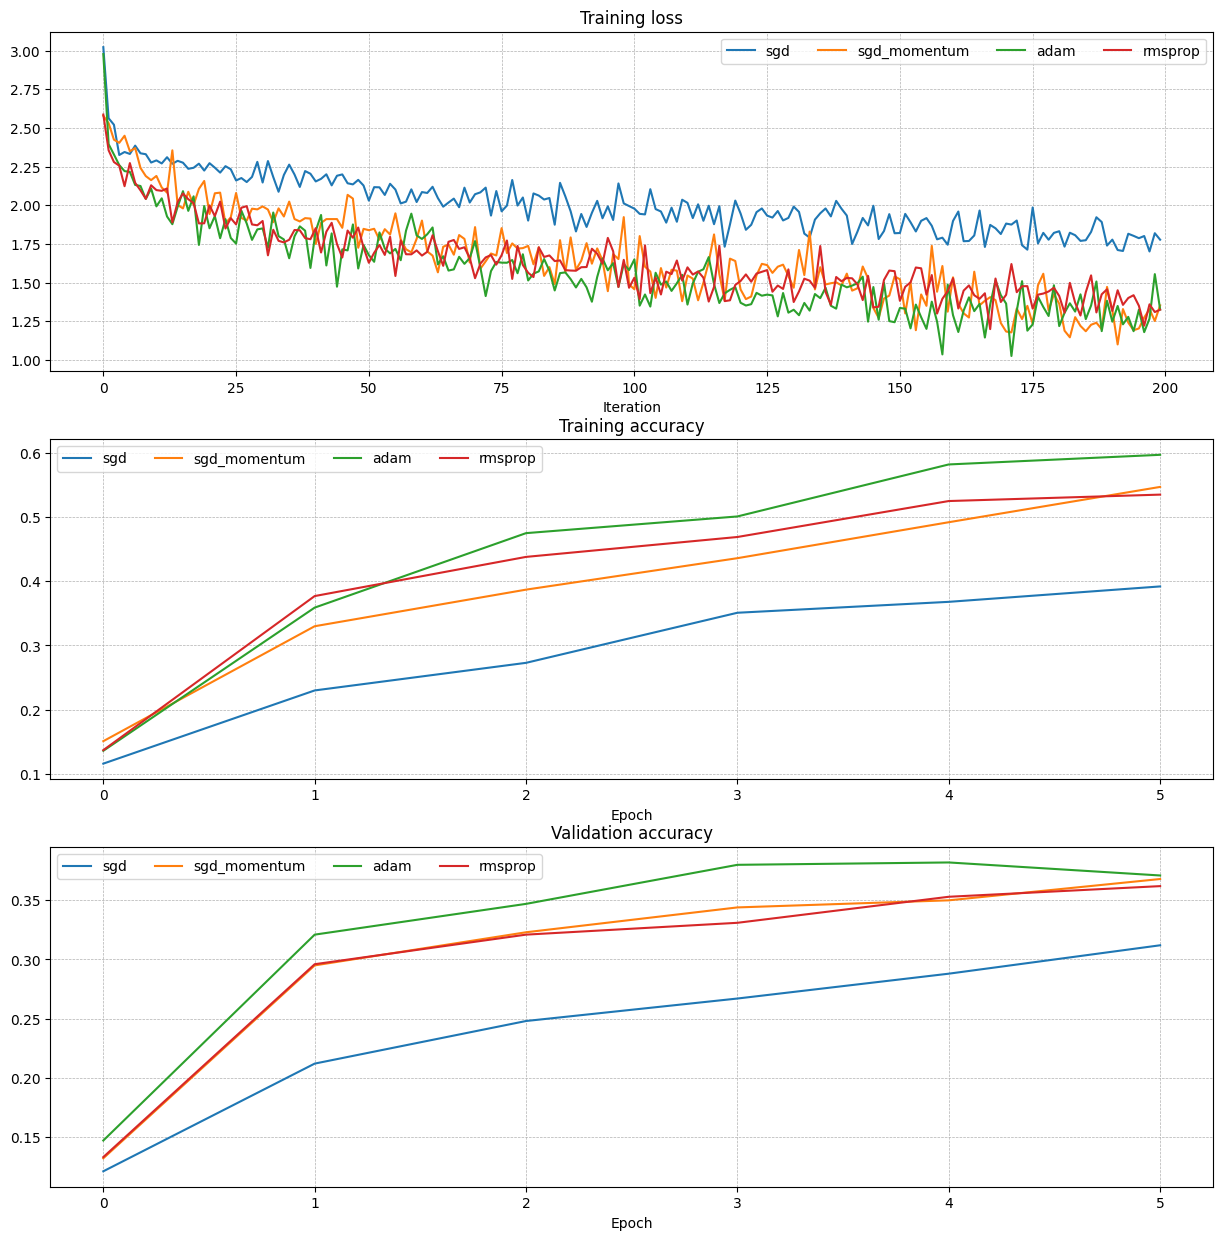

In [17]:
learning_rates = {'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['adam', 'rmsprop']:
    print('Running with ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )
    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': learning_rates[update_rule]},
        verbose=True
    )
    solvers[update_rule] = solver
    solver.train()
    print()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"{update_rule}")

for ax in axes:
    ax.legend(loc='best', ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## Inline Question 2:

AdaGrad, like Adam, is a per-parameter optimization method that uses the following update rule:

```
cache += dw**2
w += - learning_rate * dw / (np.sqrt(cache) + eps)
```

John notices that when he was training a network with AdaGrad that the updates became very small, and that his network was learning slowly. Using your knowledge of the AdaGrad update rule, why do you think the updates would become very small? Would Adam have the same issue?


## Answer:
During each training step $dw^2$ the square of gradients (which is always non-negative bcos of the square) of that step gets added into the cache. The cache at nth training step is effectively sum of squares of gradients from step 1,2... and sicne we only add positve values it grows monotonically. In the update step this ever-growing cache appear in the denominator  ($\sqrt{cache}$) keeps getting bigger and bigger, making the effective learning rate ($learning rate / $\sqrt(cache)$) shrink towards zero over time. This is why the nework stops learning.

Adam handles the issue by replacing the raw sum of squares of gradients with an exponential moving average of squared gradients. This causes the old gradients to decay away keeping the denominator bounded regardless of how long the training runs. As a result the effective learning rate stays reasonable throughout training.

# Train a Good Model!
Train the best fully connected model that you can on CIFAR-10, storing your best model in the `best_model` variable. We require you to get at least 50% accuracy on the validation set using a fully connected network.

If you are careful it should be possible to get accuracies above 55%, but we don't require it for this part and won't assign extra credit for doing so. Later in the next assignment, we will ask you to train the best convolutional network that you can on CIFAR-10, and we would prefer that you spend your effort working on convolutional networks rather than fully connected networks.

**Note:** In the next assignment, you will learn techniques like BatchNormalization and Dropout which can help you train powerful models.

### Design Choices

We tried to overfit the model using smaller dataset. This exercise is done to determine the model `complexity(layers)` and number of training `epochs` for the model. 

We decided to use `Adam` for update step and performed a coarse parameter search. The theoretical value of `1e-3` has yielded better result.

We performed hyper-parameter search on the weight initalization. The range of values between `1e-2` and `5e-3` yeilds similar results. We will be choosing `1e-2` as the final value

> The network performance does not improve beyond **5 layers** and **20 epochs**

**Experiments**
Theoretically in fully connected nets, a design of decreasing layers width as we go deep works well for classification models. As the models can learn the reperesentations that will map the inputs to the classes. So we experimented with a setting 
1. `Layers: [256, 128, 64, 32, 16], lr = 1e-3, ws = 3e-2` resulted in **val accuracy ~ 0.4**
2. `Layers: [256, 128, 64, 32, 16], lr = 5e-4, ws = 3e-2` resulted in **val accuracy >= 0.4**
3. `Layers: [256, 128, 64, 32, 16], lr = 2e-3, ws = 3e-2, batchnorm` resulted in **val accuracy >= 0.4**




[512, 256, 128, 64, 32]

Size Datasets
No. Training Examples:  49000
No. Validation Examples:  1000
No. Test Examples:  1000
Running with  adam
(Iteration 1 / 9800) loss: 2.693795
(Epoch 0 / 20) train acc: 0.104000; val_acc: 0.111000
(Iteration 11 / 9800) loss: 2.585324
(Iteration 21 / 9800) loss: 2.499171
(Iteration 31 / 9800) loss: 2.392439
(Iteration 41 / 9800) loss: 2.241439
(Iteration 51 / 9800) loss: 2.202527
(Iteration 61 / 9800) loss: 2.192387
(Iteration 71 / 9800) loss: 2.031923
(Iteration 81 / 9800) loss: 1.938047
(Iteration 91 / 9800) loss: 2.060756
(Iteration 101 / 9800) loss: 2.011389
(Iteration 111 / 9800) loss: 2.048853
(Iteration 121 / 9800) loss: 2.031507
(Iteration 131 / 9800) loss: 1.802672
(Iteration 141 / 9800) loss: 1.839687
(Iteration 151 / 9800) loss: 1.921331
(Iteration 161 / 9800) loss: 2.124708
(Iteration 171 / 9800) loss: 1.896340
(Iteration 181 / 9800) loss: 1.784931
(Iteration 191 / 9800) loss: 2.009064
(Iteration 201 / 9800) loss: 1.878992
(Iteration 211 / 9800) loss: 1.930068
(I

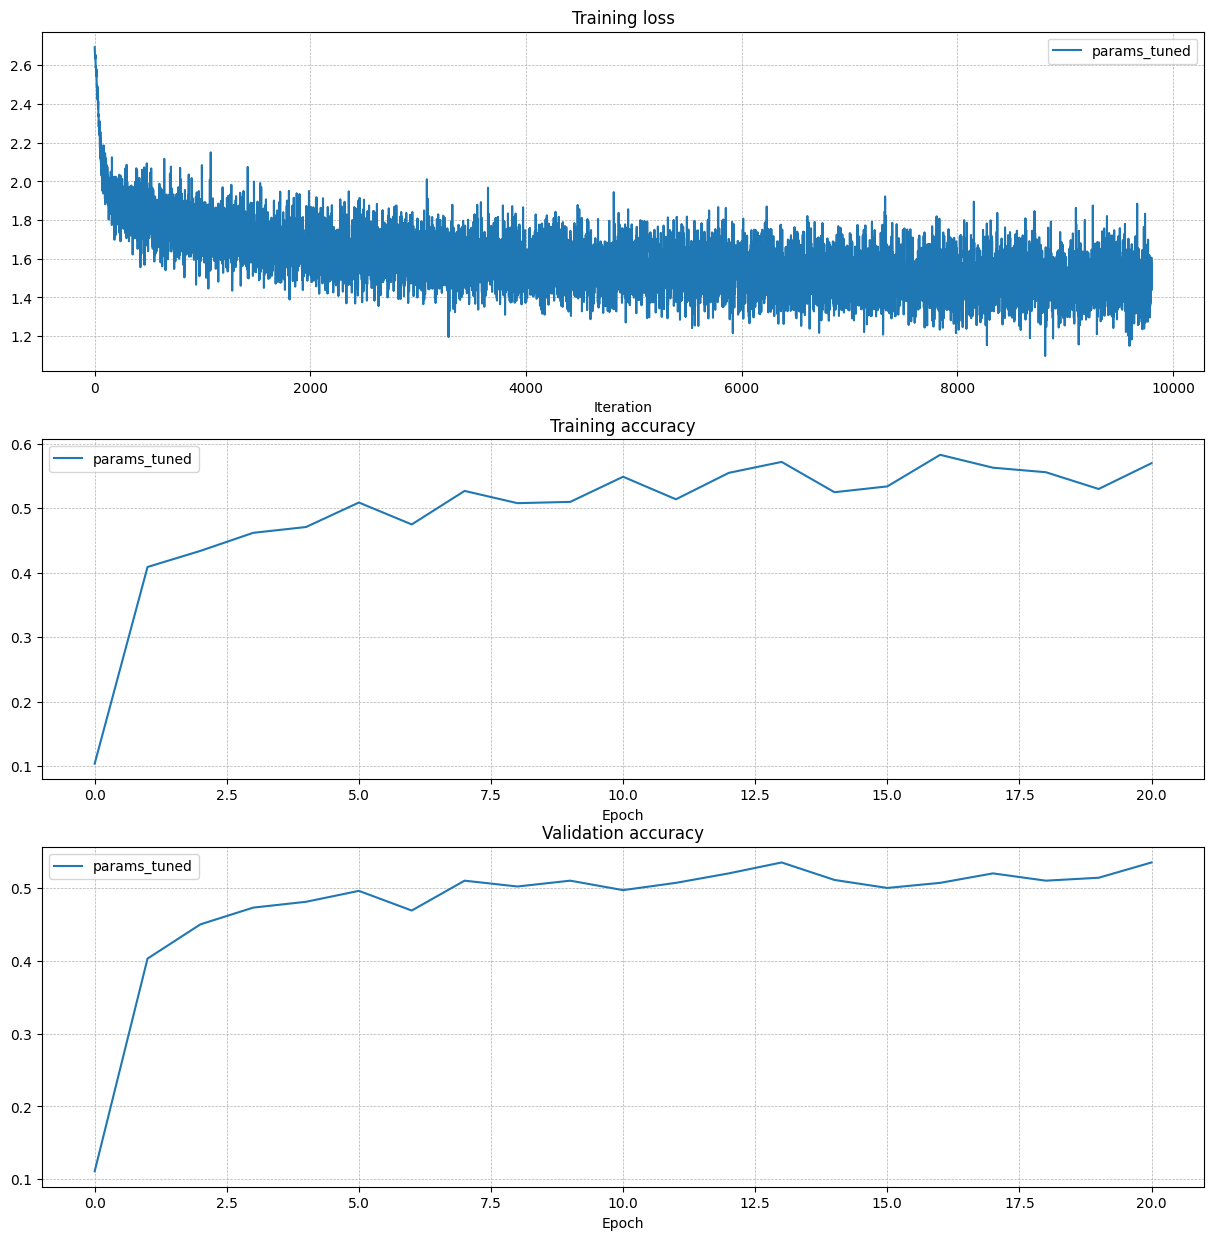

In [ ]:
best_model = None

################################################################################
# TODO: Train the best FullyConnectedNet that you can on CIFAR-10. You might   #
# find batch/layer normalization and dropout useful. Store your best model in  #
# the best_model variable.                                                     #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}
# hyperparams
update_rule = 'adam'
learning_rates = [2e-3] #np.geomspace(1e-3, 1e-2, 5)
weight_scales = [3e-2] #np.geomspace(8e-2, 1e-2, 5)


for lr in learning_rates:
# for ws in weight_scales:
    # lr = learning_rates[0]
    ws=weight_scales[0]
    print('Running with ', update_rule)
    model = FullyConnectedNet(
        [256, 128, 64, 32, 16],
        weight_scale=ws, #5e-2
        normalization="batchnorm",
        reg = 1e-3
    )
    solver = Solver(
        model,
        small_data,
        num_epochs=20,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': lr},
        verbose=True
    )
    solvers['params_tuned'] = solver
    solver.train()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for lr, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"{lr}")
    axes[1].plot(solver.train_acc_history, label=f"{lr}")
    axes[2].plot(solver.val_acc_history, label=f"{lr}")

for ax in axes:
    ax.legend(loc='best', ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)


print("Best Validation Accuracy: ", solvers['params_tuned'].best_val_acc)


plt.show()

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                              END OF YOUR CODE                                #
################################################################################

In [ ]:
# Tuned model training on full dataset
print("Size Datasets")
print("No. Training Examples: ", data['X_train'].shape[0])
print("No. Validation Examples: ", data['X_val'].shape[0])
print("No. Test Examples: ", data['X_test'].shape[0])

ws = 3e-2
lr = 2e-3

best_model = FullyConnectedNet(
    [256, 128, 64, 32, 16],
    weight_scale=ws, 
    normalization="batchnorm",
    reg = 1e-3
)
solver = Solver(
    best_model,
    data,
    num_epochs=20,
    batch_size=100,
    update_rule=update_rule,
    optim_config={'learning_rate': lr},
    verbose=True
)
solvers['params_tuned'] = solver
solver.train()

best_model.params = solver.best_params
# Solver does not store the best batch norm bn_params.
# The following code computes the best batch norm bn_params.
for bp in best_model.bn_params:
    bp['running_mean'] = np.zeros_like(bp['running_mean'])
    bp['running_var'] = np.ones_like(bp['running_var'])

for i in range(0, data['X_train'].shape[0], 100):
    best_model.loss(data['X_train'][i:i+100], data['y_train'][i:i+100])

print("Best Validation Accuracy: ", solver.best_val_acc)

Size Datasets
No. Training Examples:  49000
No. Validation Examples:  1000
No. Test Examples:  1000
(Iteration 1 / 9800) loss: 2.668883
(Epoch 0 / 20) train acc: 0.091000; val_acc: 0.113000
(Iteration 11 / 9800) loss: 2.583220
(Iteration 21 / 9800) loss: 2.498362
(Iteration 31 / 9800) loss: 2.386957
(Iteration 41 / 9800) loss: 2.281773
(Iteration 51 / 9800) loss: 2.197436
(Iteration 61 / 9800) loss: 2.069146
(Iteration 71 / 9800) loss: 2.005670
(Iteration 81 / 9800) loss: 2.073678
(Iteration 91 / 9800) loss: 2.019783
(Iteration 101 / 9800) loss: 1.939935
(Iteration 111 / 9800) loss: 1.933960
(Iteration 121 / 9800) loss: 1.861948
(Iteration 131 / 9800) loss: 2.096959
(Iteration 141 / 9800) loss: 1.996252
(Iteration 151 / 9800) loss: 1.880401
(Iteration 161 / 9800) loss: 1.933591
(Iteration 171 / 9800) loss: 1.885505
(Iteration 181 / 9800) loss: 1.907951
(Iteration 191 / 9800) loss: 2.029451
(Iteration 201 / 9800) loss: 1.921411
(Iteration 211 / 9800) loss: 1.901194
(Iteration 221 / 9800

# Test Your Model!
Run your best model on the validation and test sets. You should achieve at least 50% accuracy on the validation set and the test set.

In [45]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Validation set accuracy: ', (y_val_pred == data['y_val']).mean())
print('Test set accuracy: ', (y_test_pred == data['y_test']).mean())

Validation set accuracy:  0.533
Test set accuracy:  0.534
